In [1]:
import os
os.chdir("..")

In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from optimizer import grid_search, strategy_compare

In [3]:
STRATEGIES = {
    "BuyHold": {"classic_dca": True},
    "Default": {},
    "Experimental1": {"extra_buy_amount": 20, "buy_embargo": 7},
    "Experimental2": {"cooldown_long": 180},
}

In [4]:
df_prices = pd.read_csv("data/test_crypto.csv", index_col=0, parse_dates=True)
df_prices.drop("DOGE", axis=1, inplace=True)
df_prices

,BTC,ETH,SOL,XRP,ADA,DOT,LINK,XLM,XMR
Date,,,,,,,,,
2014-09-17,457.334015,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2014-09-18,424.440002,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2014-09-19,394.795990,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2014-09-20,408.903992,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2014-09-21,398.821014,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
...,...,...,...,...,...,...,...,...,...
2026-10-20,82941.000000,2446.730713,106.422340,1.334452,0.223782,1.149771,12.320927,0.181960,600.929504
2026-10-21,84011.968750,2470.766113,106.793655,1.363619,0.224979,1.141323,12.484719,0.183488,622.434082
2026-10-22,81311.890625,2386.189209,103.542320,1.307656,0.212025,1.111869,11.943166,0.175209,600.638428


# COMPARE

In [5]:
history_compare = strategy_compare(
    prices=df_prices,
    strategies=STRATEGIES,
    n_boot=100,
    sample_size=10,
    sequence_length=365 * 4,
)

100%|██████████| 4/4 [03:05<00:00, 46.27s/it]


In [6]:
history_compare

,strategy,Target,Cash_spent,Realized_cash,Portfolio,Invested,Total_value,Bull_history,Avg_price,Num_take_profits,MDD,MA200_survival_days,RoAC,iteration
0,BuyHold,ADA,2059,0,3549,2059,3549,90,0.145388,0,-32330,369.000000,616,1
1,BuyHold,ETH,2069,0,22687,2069,22687,61,299.291538,0,-16430,62.500000,311,1
2,BuyHold,ADA,2069,0,2271,2069,2271,72,0.373575,0,-6015,179.000000,172,1
3,BuyHold,XMR,2069,0,4267,2069,4267,70,182.424374,0,-4583,18.705882,30,1
4,BuyHold,XLM,2069,0,1771,2069,1771,46,0.131088,0,-2295,162.000000,40,1
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
3995,Experimental2,LINK,2059,8911,496,587,9407,93,8.608842,6,-3063,0.000000,1071,100
3996,Experimental2,DOT,2554,0,800,2554,800,26,2.568859,9,-1694,0.000000,-15,100
3997,Experimental2,XLM,2069,2278,1099,1032,3377,63,0.173639,2,-1914,40.666667,108,100
3998,Experimental2,ADA,2187,1848,625,1383,2473,49,0.358456,4,-1040,0.000000,84,100


In [7]:
compare_res = history_compare.groupby("strategy").agg(
    RoAC=("RoAC", "mean"),
    MDD=("MDD", "mean"),
    Portfolio=("Portfolio", "mean"),
    Realized_cash=("Realized_cash", "mean"),
    Cash_spent=("Cash_spent", "mean"),
    Total_value_mean=("Total_value", "mean"),
    Total_value_median=("Total_value", "median"),
    Total_value_low=("Total_value", lambda s: np.percentile(s, 25)),
    Total_value_high=("Total_value", lambda s: np.percentile(s, 75)),
)

compare_res['Uncle'] = compare_res['MDD'] / compare_res['Total_value_mean']
compare_res.sort_values("RoAC", ascending=False).style.background_gradient(cmap="RdYlGn", axis=0).format("{:.2f}")

,RoAC,MDD,Portfolio,Realized_cash,Cash_spent,Total_value_mean,Total_value_median,Total_value_low,Total_value_high,Uncle
strategy,,,,,,,,,,
Default,332.57,-1305.81,1104.25,3637.07,2169.32,4741.77,4253.50,3214.00,5663.25,-0.28
Experimental1,304.62,-1266.55,1098.05,3384.13,2136.27,4482.63,4137.50,3164.00,5455.50,-0.28
Experimental2,263.65,-2268.60,1420.33,3585.10,2156.47,5005.88,4399.50,3340.75,6176.50,-0.45
BuyHold,181.94,-11047.02,6314.92,0.00,2064.57,6314.92,3519.50,2227.50,6948.75,-1.75


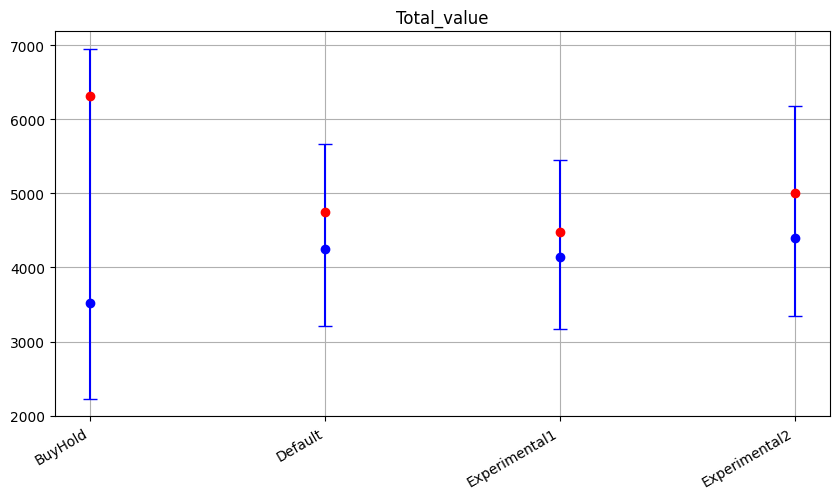

In [8]:
metric = "Total_value"

plt.figure(figsize=(10, 5))

median = compare_res[f"{metric}_median"]
mean = compare_res[f"{metric}_mean"]
low = compare_res[f"{metric}_low"]
high = compare_res[f"{metric}_high"]

plt.errorbar(
    median.index,
    median.values,
    yerr=[median - low, high - median],
    fmt="o",
    capsize=5,
    label="median",
    color="blue",
)
plt.errorbar(
    mean.index,
    mean.values,
    fmt="o",
    capsize=5,
    label="mean",
    color="red",
)
plt.title(metric)
plt.xticks(rotation=30, ha="right")
plt.grid()
plt.show()